In [1]:
import pandas as pd
import numpy as np
from vis.utils_motifs import motif_to_fwords
from collections import Counter
import ast
import matplotlib.pyplot as plt
import torch
import math

### 1. Analyze motifs per class

In [ ]:
file_name = r"\results\run_GCN_persuade_wan_cooc_qwen2515b_wan-w5_nf-count+freq+emb_ew-wan_sp-random_L2_H64_sum_lr0.001_seed2026\motif_comparison_topk20.csv"
df = pd.read_csv(file_name)
df

FileNotFoundError: [Errno 2] No such file or directory: '\\results\\run_GCN_persuade_wan_cooc_qwen2515b_wan-w5_nf-count+freq+emb_ew-wan_sp-random_L2_H64_sum_lr0.001_seed2026\\explanations_none_object_motif_comparison_topk20.csv'

In [3]:
human_selected = df["human_selected"] > 0
machine_selected = df["machine_selected"] > 0

human_only = (human_selected & ~machine_selected).sum()
machine_only = (~human_selected & machine_selected).sum()
shared = (human_selected & machine_selected).sum()

total = (human_selected | machine_selected).sum()

print(f"TOtal unique selected motifs: {total}")
print(f"Human only: {human_only}")
print(f"Machine only: {machine_only}")
print(f"Shared: {shared}")

TOtal unique selected motifs: 6830
Human only: 4037
Machine only: 2729
Shared: 64


In [4]:
fwords_df = pd.read_csv(r"data\function_words_277.csv")
fwords = fwords_df["word"].tolist()

In [5]:
df["motif_fwords"] = df["motif"].apply(
    lambda m: motif_to_fwords(m, fwords)
)

In [6]:
df

,motif,human_present,human_selected,human_rate,machine_present,machine_selected,machine_rate,difference,motif_fwords
0,"((10, 61), (61, 51))",2,0,0.000000,1,1,1.0,1.0,"(alone, eg) (eg, could)"
1,"((10, 62), (95, 62))",2,0,0.000000,1,1,1.0,1.0,"(alone, either) (hereunder, either)"
2,"((104, 113), (113, 112))",1,1,1.000000,1,0,0.0,-1.0,"(however, is) (is, into)"
3,"((104, 59), (104, 64))",1,0,0.000000,1,1,1.0,1.0,"(however, during) (however, elsewhere)"
4,"((10, 52), (103, 10))",2,0,0.000000,1,1,1.0,1.0,"(alone, dare) (how, alone)"
...,...,...,...,...,...,...,...,...,...
6825,"((113, 63), (113, 80))",3,1,0.333333,0,0,NaN,NaN,"(is, else) (is, further)"
6826,"((113, 72), (113, 111))",2,1,0.500000,0,0,NaN,NaN,"(is, everywhere) (is, instead)"
6827,"((113, 91), (113, 92))",1,1,1.000000,0,0,NaN,NaN,"(is, hereby) (is, herein)"
6828,"((113, 91), (113, 112))",1,1,1.000000,0,0,NaN,NaN,"(is, hereby) (is, into)"


In [7]:
h = df[
    (df["human_selected"] > 0) &
    (df["machine_selected"] == 0)
]

m = df[
    (df["human_selected"] == 0) &
    (df["machine_selected"] > 0)
]

print("Human-only motifs selected once:",
      (h["human_selected"] == 1).sum())

print("Machine-only motifs selected once:",
      (m["machine_selected"] == 1).sum())

Human-only motifs selected once: 3938
Machine-only motifs selected once: 2566


In [9]:
motif_results = torch.load(
    r"results\run_GCN_persuade_wan_cooc_qwen2515b_wan-w5_nf-count+freq+emb_ew-wan_sp-random_L2_H64_sum_lr0.001_seed2026\motif_2edges_top_k20.pth",
    map_location="cpu",
    weights_only=False
)

In [10]:
print(type(motif_results))

<class 'list'>


In [11]:
df_graphs = pd.DataFrame(motif_results)
df_graphs

,row,label,pred,motifs,num_motifs
0,13,0,0,"[((0, 5), (5, 7)), ((0, 5), (5, 59)), ((0, 5),...",26
1,17,0,0,"[((7, 4), (7, 80)), ((7, 4), (8, 4)), ((7, 4),...",18
2,20,0,0,"[((0, 80), (28, 80)), ((0, 80), (74, 80)), ((0...",26
3,22,0,0,"[((0, 5), (10, 0)), ((2, 80), (10, 80)), ((2, ...",38
4,28,0,0,"[((0, 39), (39, 0)), ((0, 39), (79, 0)), ((0, ...",19
...,...,...,...,...,...
355,2372,1,1,"[((0, 5), (1, 5)), ((1, 5), (85, 1)), ((10, 12...",29
356,2379,1,1,"[((0, 27), (0, 102)), ((0, 102), (102, 29)), (...",20
357,2381,1,1,"[((2, 74), (28, 2)), ((3, 92), (23, 92)), ((4,...",12
358,2383,1,1,"[((0, 92), (15, 0)), ((0, 92), (81, 92)), ((1,...",10


In [12]:
df_graphs = df_graphs[
    df_graphs["label"] == df_graphs["pred"]
]

df_graphs["class"] = df_graphs["label"].map({
    0: "Human",
    1: "Machine"
})

display(
    df_graphs.groupby("class")["num_motifs"].agg(
        ["count", "sum", "mean", "median", "min", "max"]
    )
)

,count,sum,mean,median,min,max
class,,,,,,
Human,180,4207,23.372222,22.0,10,44
Machine,178,3032,17.033708,14.0,5,64


In [13]:
results = torch.load(
    r"results\run_GCN_persuade_wan_cooc_qwen2515b_wan-w5_nf-count+freq+emb_ew-wan_sp-random_L2_H64_sum_lr0.001_seed2026\explanations_none_object.pth",
    map_location="cpu",
    weights_only=False
)

In [14]:
rows = []

for result in results:

    if result["label"] != result["pred"]:
        continue

    edge_index = result["edge_index"]

    num_edges = (edge_index[0] != edge_index[1]).sum().item()

    rows.append({
        "class": "Human" if result["label"] == 0 else "Machine",
        "num_edges": num_edges
    })

df_edges = pd.DataFrame(rows)

display(
    df_edges.groupby("class")["num_edges"].agg(
        ["count", "mean", "median", "min", "max"]
    )
)

,count,mean,median,min,max
class,,,,,
Human,180,364.477778,331.0,122,895
Machine,178,160.410112,160.5,40,325


In [15]:
selected_results = torch.load(
    r"results\run_GCN_persuade_wan_cooc_qwen2515b_wan-w5_nf-count+freq+emb_ew-wan_sp-random_L2_H64_sum_lr0.001_seed2026\motif_edges_top_k20.pth",
    map_location="cpu",
        weights_only=False
)

In [16]:
rows = []

for selected, motif_result in zip(selected_results, motif_results):

    if selected["row"] != motif_result["row"]:
        raise ValueError("Graph order does not match")

    if selected["label"] != selected["pred"]:
        continue

    edges = {
        (int(u), int(v))
        for u, v in selected["edge_index"].T.tolist()
        if u != v
    }

    k = len(edges)

    M = motif_result["num_motifs"]

    possible_pairs = math.comb(k, 2)

    interconnectedness = (
        M / possible_pairs
        if possible_pairs > 0 else float("nan")
    )

    rows.append({
        "class": "Human" if selected["label"] == 0 else "Machine",
        "selected_edges": k,
        "num_motifs": M,
        "possible_pairs": possible_pairs,
        "interconnectedness": interconnectedness
    })

df_connectivity = pd.DataFrame(rows)

In [17]:
display(
    df_connectivity.groupby("class")[
        ["selected_edges", "num_motifs", "interconnectedness"]
    ].agg(["mean", "median"])
)

selected_edges        num_motifs        interconnectedness          
                  mean median       mean median               mean    median
class                                                                       
Human             20.0   20.0  23.372222   22.0           0.123012  0.115789
Machine           20.0   20.0  17.033708   14.0           0.089651  0.073684

### 2. Analyze words in the motifs per class

In [18]:
def count_function_words(df, column, fwords):
    counts = Counter()

    for _, row in df[df[column] > 0].iterrows():
        motif = row["motif"]

        if isinstance(motif, str):
            motif = ast.literal_eval(motif)

        nodes = {
            node 
            for edge in motif
            for node in edge
        }

        for node in nodes:
            counts[fwords[node]] += 1
            
    return pd.DataFrame(
        counts.most_common(),
        columns=["word", "count"]
    )
    

In [19]:
human_words = count_function_words(df, "human_selected", fwords)
human_words

,word,count
0,further,935
1,herein,783
2,a,618
3,afterwards,478
4,from,421
...,...,...
98,be,6
99,hereafter,6
100,except,5
101,do,2


In [20]:
machine_words = count_function_words(df, "machine_selected", fwords)
machine_words

,word,count
0,herein,536
1,further,432
2,eg,405
3,afterwards,381
4,behind,372
...,...,...
95,hereinafter,2
96,hereafter,1
97,another,1
98,herself,1


In [21]:
word_comparison = human_words.rename(
    columns={"count": "human_count"}
    ).merge(
        machine_words.rename(
            columns={"count": "machine_count"}
        ),
        on="word",
        how="outer"
    ).fillna(0)

word_comparison["difference"] = (
    word_comparison["human_count"] - word_comparison["machine_count"]
)

word_comparison


,word,human_count,machine_count,difference
0,a,618.0,232.0,386.0
1,about,76.0,99.0,-23.0
2,above,94.0,40.0,54.0
3,across,10.0,40.0,-30.0
4,after,61.0,89.0,-28.0
...,...,...,...,...
102,inside,11.0,65.0,-54.0
103,instead,131.0,52.0,79.0
104,into,310.0,8.0,302.0
105,is,92.0,14.0,78.0


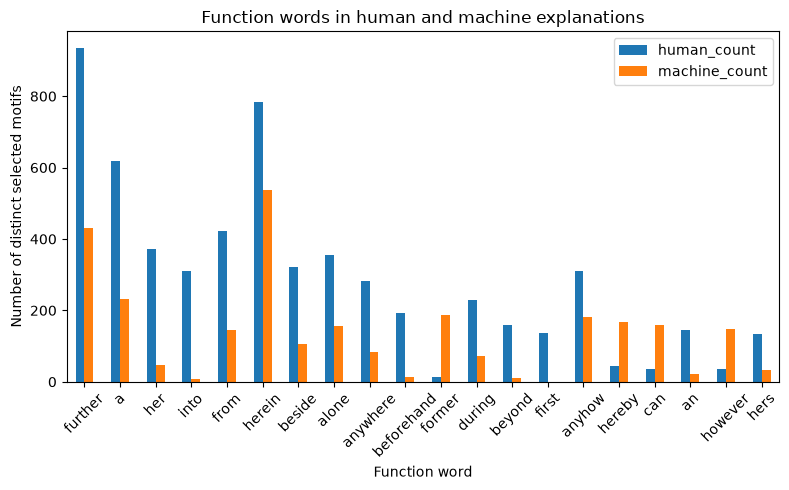

In [24]:
top_words = word_comparison.sort_values(
    "difference",
    key=abs,
    ascending=False
).head(20)

top_words = top_words.set_index("word")

top_words[["human_count", "machine_count"]].plot(
    kind="bar",
    figsize=(8,5)
)

plt.xlabel("Function word")
plt.ylabel("Number of distinct selected motifs")
plt.title("Function words in human and machine explanations")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()